In [51]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()

In [52]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

soda_challenge_path = kagglehub.competition_download('soda-challenge')

print('Data source import complete.')

Data source import complete.


# 🌴 SODA Challenge — Date Fruit Image Classification


| الرقم الجامعي |  الاسم |
|---|---|
|446002942|  لمار محمد الغامدي |
|446003470 | ساره منصور المالكي|
|446007287 | رتاج محمد  الهوساوي|
|446002873 | نوره سالم القرباني|

---
## 📋 Project Pipeline
```
1️⃣  Data Understanding & EDA
        ↓
2️⃣  Data Preprocessing
        ↓
3️⃣  Feature Extraction (ResNet50)
        ↓
4️⃣  Model 1 — Random Forest Classifier
        ↓
5️⃣  Model 2 — XGBoost Classifier
        ↓
6️⃣  Model 3 — ResNet50 Transfer Learning (Deep Learning)
        ↓
7️⃣  Evaluation & Comparison (all 3 models)
        ↓
8️⃣  Submission (best model)
```


---
## 🎯 Problem Definition

**Task:** Multi-class Image Classification  
**Goal:** Given an image of a date fruit, predict which of the **13 types** it belongs to  
**Input:** RGB image (resized to 224×224×3)  
**Output:** Class label from 1 to 13  
**Evaluation Metric:** Accuracy, Precision, Recall, F1-score  

**Why Classification?**  
The target variable (`label`) is categorical — 13 discrete date fruit types.  
This is a **supervised multi-class classification** problem.

**Libraries Used:**

| Library | Purpose |
|---|---|
| TensorFlow / Keras | Deep learning models (ResNet50) |
| Scikit-learn | Classical ML models (RF, GB) + metrics |
| OpenCV (cv2) | Image loading and resizing |
| NumPy | Array operations |
| Pandas | CSV loading and data handling |
| Matplotlib / Seaborn | Visualization |

---
## 📦 Section 0: Import Libraries

In [53]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # hide TF warnings

import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
tf.get_logger().setLevel('ERROR')

print('✅ Libraries loaded')

✅ Libraries loaded


In [55]:
import numpy as np
import pandas as pd
import os
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten,
    Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

import warnings
warnings.filterwarnings('ignore')

print('✅ Libraries imported successfully')

# ── Expected output ─────────────────────────────────────────────────────────
# ✅ Libraries imported successfully

✅ Libraries imported successfully


---
## 1️⃣ Section 1: Data Understanding & Exploration (EDA)
> **الهدف:** نفهم البيانات قبل أي خطوة  
> - كم صورة عندنا؟  
> - كم نوع تمر؟  
> - هل البيانات متوازنة؟

In [58]:
# ── Load CSV Files ────────────────────────────────────────────────────────────
train             = pd.read_csv('/kaggle/input/competitions/soda-challenge/soda_dataset/train.csv')
test              = pd.read_csv('/kaggle/input/competitions/soda-challenge/soda_dataset/test.csv')
sample_submission = pd.read_csv('/kaggle/input/competitions/soda-challenge/soda_dataset/sample_submission.csv')

print('=== Train ===')
print(f'Shape: {train.shape}')   # (1829, 2)
print(train.head())
#    id  label
# 0   1     13
# 1   2      1
# ...

print('\n=== Test ===')
print(f'Shape: {test.shape}')    # (784, 1)
print(test.head())

print('\n=== Sample Submission ===')
print(sample_submission.head())
#    id  label
# 0   1      1
# 1   2      2

=== Train ===
Shape: (1829, 2)
   id  label
0   1     13
1   2      1
2   3     11
3   4     11
4   5      2

=== Test ===
Shape: (784, 1)
   id
0   1
1   2
2   3
3   4
4   5

=== Sample Submission ===
   id  label
0   1      1
1   2      2
2   3      1
3   4      3
4   5      2


In [59]:
# ── Basic Info ────────────────────────────────────────────────────────────────
print(train.info())
# id       int64
# label    int64   ← 13 unique values (1 to 13)

print('\n')
print(train.describe())
# label: min=1, max=13, mean≈7

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1829 entries, 0 to 1828
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      1829 non-null   int64
 1   label   1829 non-null   int64
dtypes: int64(2)
memory usage: 28.7 KB
None


                id        label
count  1829.000000  1829.000000
mean    915.000000     6.995626
std     528.131139     3.744139
min       1.000000     1.000000
25%     458.000000     4.000000
50%     915.000000     7.000000
75%    1372.000000    10.000000
max    1829.000000    13.000000


In [60]:
# ── Missing Values & Duplicates ───────────────────────────────────────────────
print('Missing values in train:', train.isnull().sum().to_dict())
# Missing values in train: {'id': 0, 'label': 0}  ← no missing values ✅

print('Duplicate rows:', train.duplicated().sum())
# Duplicate rows: 0  ← no duplicates ✅

Missing values in train: {'id': 0, 'label': 0}
Duplicate rows: 0


In [61]:
# ── Class Distribution ────────────────────────────────────────────────────────
print('=== Class Distribution ===')
print(train['label'].value_counts().sort_index())
# label
# 1     141
# 2     141
# 3     141
# ...   (well balanced, 140–141 per class)

print(f'\nNumber of classes: {train["label"].nunique()}')
# Number of classes: 13


=== Class Distribution ===
label
1     141
2     141
3     141
4     141
5     141
6     140
7     141
8     140
9     141
10    140
11    141
12    140
13    141
Name: count, dtype: int64

Number of classes: 13


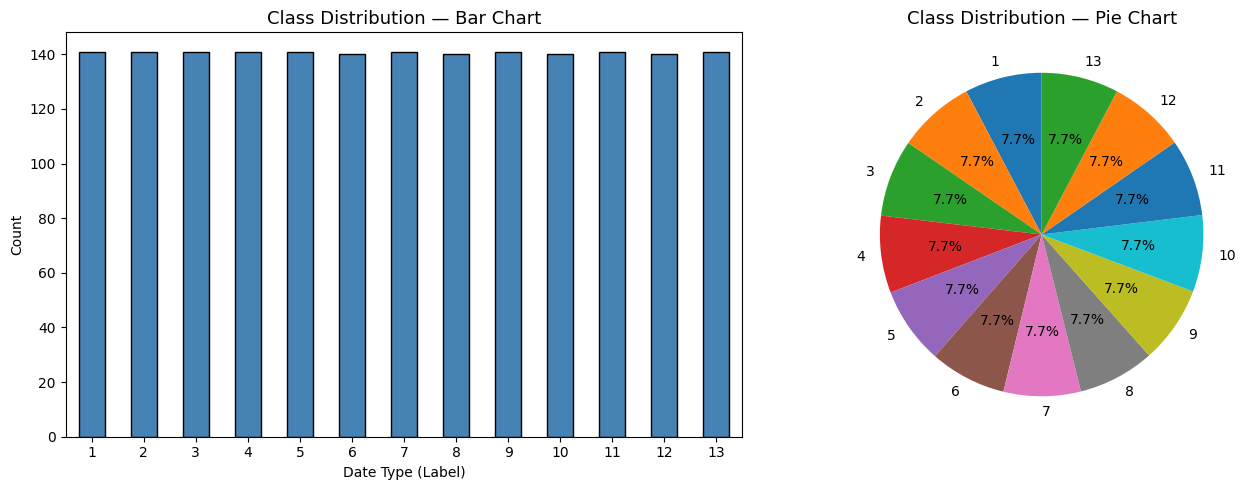

In [9]:
# ── Plot: Class Distribution ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
train['label'].value_counts().sort_index().plot(
    kind='bar', ax=axes[0], color='steelblue', edgecolor='black'
)
axes[0].set_title('Class Distribution — Bar Chart', fontsize=13)
axes[0].set_xlabel('Date Type (Label)')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)

# Pie chart
train['label'].value_counts().sort_index().plot(
    kind='pie', ax=axes[1], autopct='%1.1f%%', startangle=90
)
axes[1].set_title('Class Distribution — Pie Chart', fontsize=13)
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

# ── What this plot shows ─────────────────────────────────────────────────────
# The dataset is fairly balanced — each class has roughly 7.7% of samples
# (13 classes × ~7.7% = 100%). No class dominates significantly.

In [10]:
# ── Check Images on Disk ──────────────────────────────────────────────────────
TRAIN_IMAGES_PATH = '/kaggle/input/competitions/soda-challenge/soda_dataset/images/train'
TEST_IMAGES_PATH  = '/kaggle/input/competitions/soda-challenge/soda_dataset/images/test'

available = os.listdir(TRAIN_IMAGES_PATH)
print(f'Image files on disk: {len(available)}')
# Image files on disk: 1829

# Check for missing images
missing = []
for img_id in train['id']:
    if f'{img_id}.jpg' not in available and f'{img_id}.png' not in available:
        missing.append(img_id)
print(f'Missing images: {len(missing)}')
# Missing images: 0  ← all images are present ✅

Image files on disk: 1829
Missing images: 0


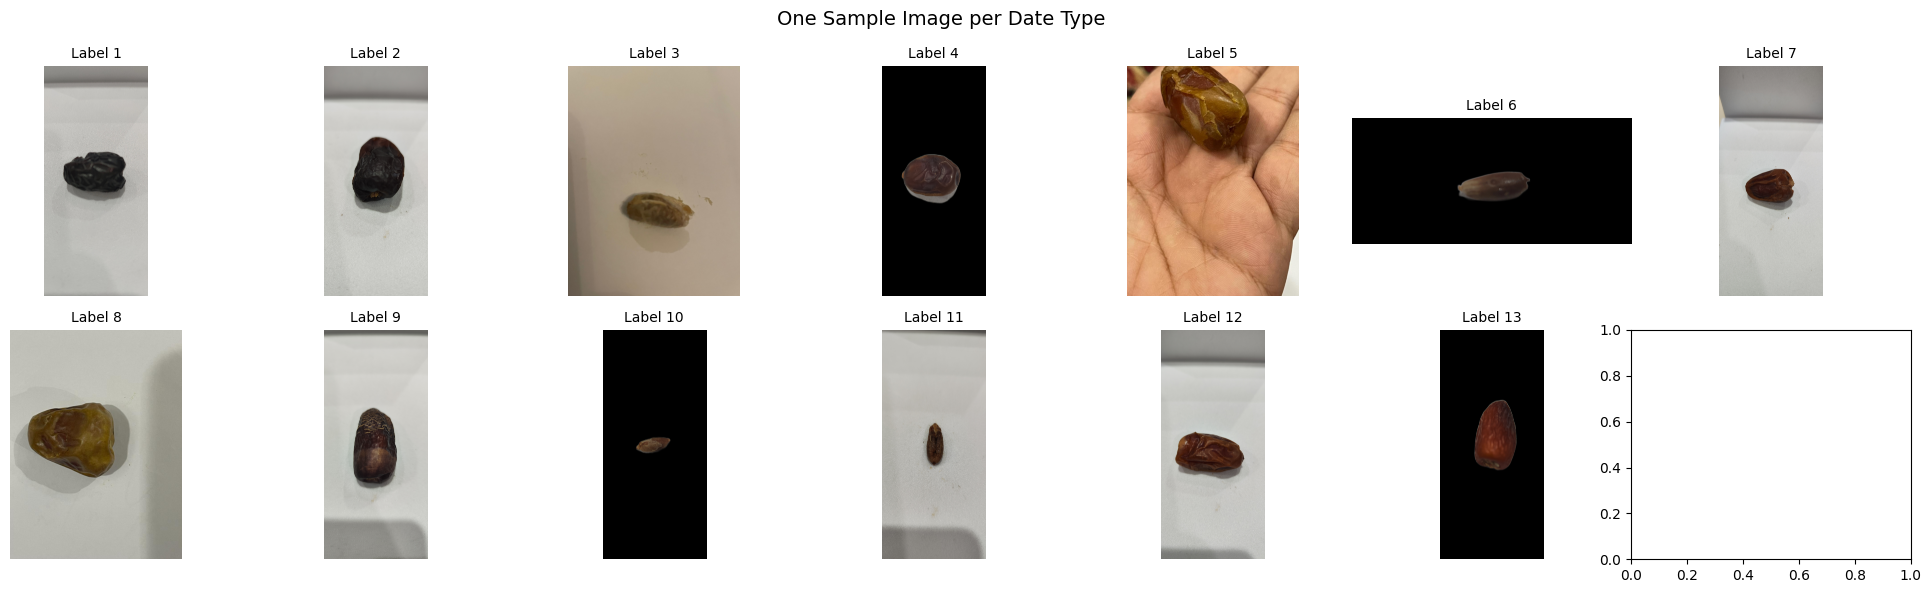

In [11]:
# ── Sample Image Per Class ────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 7, figsize=(20, 6))
axes = axes.flatten()

for idx, label in enumerate(sorted(train['label'].unique())):
    sample_id = train[train['label'] == label]['id'].iloc[0]
    for ext in ['.jpg', '.png']:
        path = os.path.join(TRAIN_IMAGES_PATH, str(sample_id) + ext)
        if os.path.exists(path):
            img = cv2.imread(path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            axes[idx].imshow(img)
            axes[idx].set_title(f'Label {label}', fontsize=10)
            axes[idx].axis('off')
            break

plt.suptitle('One Sample Image per Date Type', fontsize=14)
plt.tight_layout()
plt.show()

# ── What this shows ───────────────────────────────────────────────────────────
# 13 different date types — visual differences include color, texture, shape.
# Some classes look similar → this is why deep learning features help.

### 🔍 EDA Findings

| Finding | Value |
|---|---|
| Training samples | 1,829 images |
| Test samples | 784 images |
| Number of classes | 13 date fruit types |
| Labels range | 1 to 13 |
| Missing values | None ✅ |
| Duplicate rows | None ✅ |
| Class balance | Roughly balanced (~140 per class) |
| Image formats | .jpg and .png mixed |

**Observation:** The dataset is well-balanced — no class dominates significantly.  
Some date types look visually similar (color, texture, shape),  
which makes this a challenging classification task requiring deep learning features.

---
## 2️⃣ Section 2: Data Preprocessing
> **الهدف:** تجهيز البيانات للموديل  
> - تحميل الصور وتحويلها إلى arrays
> - تطبيع البكسلز
> - **إصلاح التسميات: 1–13 → 0–12** ← هذا الإصلاح يحل خطأ ResNet50
> - تقسيم train/validation

In [62]:
# ── Load & Resize All Images ──────────────────────────────────────────────────
IMG_SIZE = 224

images_list = []
labels_list = []

for _, row in train.iterrows():
    img_id = str(row['id'])
    for ext in ['.jpg', '.png']:
        path = os.path.join(TRAIN_IMAGES_PATH, img_id + ext)
        if os.path.exists(path):
            img = cv2.imread(path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # BGR → RGB
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))  # resize to 224×224
            images_list.append(img)
            labels_list.append(row['label'])
            break

# Normalize to [0,1] — required before preprocess_input(X * 255) in feature extraction
X = np.array(images_list).astype('float32') / 255.0
y = np.array(labels_list)

print(f'Images shape: {X.shape}')              # (1829, 224, 224, 3)
print(f'Pixel range:  {X.min():.1f} – {X.max():.1f}')  # 0.0 – 1.0
print(f'Labels range: {y.min()} to {y.max()}')  # 1 to 13


Images shape: (1829, 224, 224, 3)
Labels shape: (1829,)
Labels range: 1 to 13


In [13]:
# ── Fix Label Range: 1–13 → 0–12 ─────────────────────────────────────────────
# ⚠️ IMPORTANT FIX:
# Original error in notebook:
#   "Received a label value of 13 which is outside the valid range of [0, 13)"
# Root cause: labels are 1–13, but sparse_categorical_crossentropy
# expects labels 0 to (num_classes - 1) = 0 to 12
# Fix: subtract 1 from all labels

y = y - 1

print(f'Labels range after fix: {y.min()} to {y.max()}')
# Labels range after fix: 0 to 12  ✅
print(f'Unique labels: {sorted(np.unique(y))}')
# Unique labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

Labels range after fix: 0 to 12
Unique labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]


In [14]:
# ── Train / Validation Split ──────────────────────────────────────────────────
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y    # ensures each split has same class proportion
)

print(f'Train:      {X_train.shape}')  # (1463, 224, 224, 3)
print(f'Validation: {X_val.shape}')    # (366, 224, 224, 3)
print(f'y_train unique labels: {sorted(np.unique(y_train))}')
# [0, 1, 2, ..., 12] — all 13 classes present in train

Train:      (1463, 224, 224, 3)
Validation: (366, 224, 224, 3)
y_train unique labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]


### ⚙️ Preprocessing Summary

| Step | Detail | Why |
|---|---|---|
| Load images | cv2.imread() + cvtColor BGR→RGB | OpenCV reads BGR by default |
| Resize | 224×224 pixels | ResNet50 requires fixed input size |
| Normalize | divide by 255 → [0,1] | Consistent scale before feature extraction |
| Fix labels | subtract 1 (1–13 → 0–12) | sparse_categorical_crossentropy needs 0-indexed labels |
| Split | 80% train / 20% validation | Standard evaluation split |
| stratify=y | Keep class balance in both sets | Prevents biased evaluation |


### 🖼️ Sample Images from Loaded Data
> Displaying 9 random samples from the training set after loading and resizing.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..21.32].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-108.68..105.061].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-115.779..109.061].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..21.060997].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-115.68..116.061].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..-13.939003].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..60.060997].
Clipping input

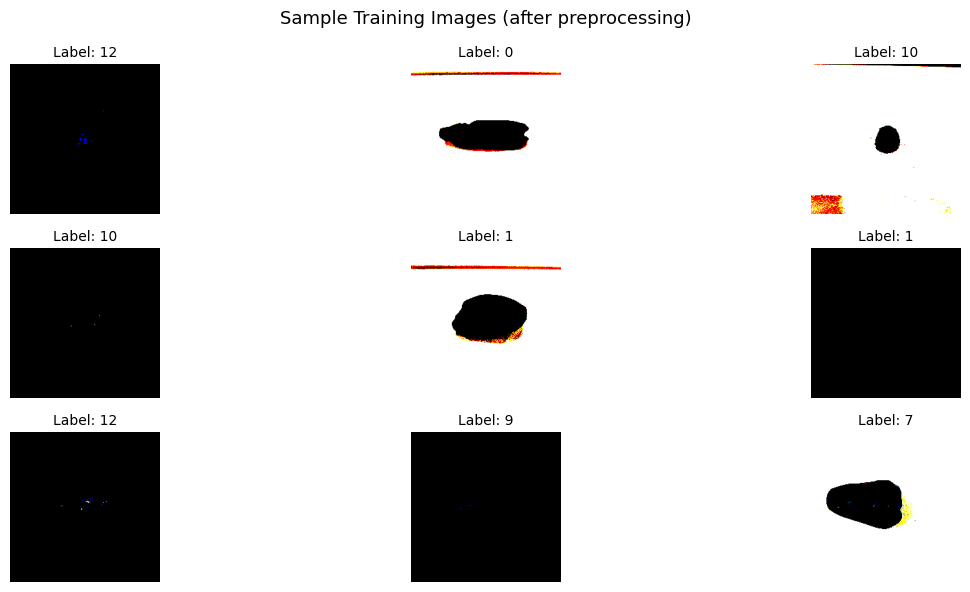

In [15]:
# ── Display Sample Images from X ────────────────────────────────────────────
plt.figure(figsize=(14, 6))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X[i])               
    plt.title(f'Label: {y[i]}', fontsize=10)
    plt.axis('off')

plt.suptitle('Sample Training Images (after preprocessing)', fontsize=13)
plt.tight_layout()
plt.show()

---
## 3️⃣ Section 3: Feature Extraction with ResNet50
> **الفكرة:** بدل تدريب CNN من الصفر، نستخدم ResNet50 المدرّب مسبقاً على ImageNet  
> كـ **feature extractor** — يحوّل كل صورة إلى vector حجمه 2048  
> هذا الـ vector يُستخدم لتدريب النماذج الكلاسيكية (RF, GB)

In [16]:
# ── Load ResNet50 as Feature Extractor ────────────────────────────────────────
feature_extractor = ResNet50(
    weights='imagenet',   # pre-trained weights on 1.2M ImageNet images
    include_top=False,    # remove the final 1000-class classification head
    pooling='avg'         # global average pooling → output: (batch, 2048)
)

print(f'Output feature size: {feature_extractor.output_shape}')
# Output feature size: (None, 2048)

I0000 00:00:1780527881.991968     637 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1780527881.997054     637 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Output feature size: (None, 2048)


In [17]:
# ── Extract Features from Train & Validation ─────────────────────────────────
# X is normalized [0,1] → multiply by 255 to restore [0,255] before preprocess_input
# preprocess_input applies ImageNet mean subtraction (channel-wise normalization)
print('Extracting train features...')
X_train_features = feature_extractor.predict(
    preprocess_input(X_train * 255), verbose=1
)

print('\nExtracting validation features...')
X_val_features = feature_extractor.predict(
    preprocess_input(X_val * 255), verbose=1
)

print(f'\nTrain features:      {X_train_features.shape}')  # (1463, 2048)
print(f'Validation features: {X_val_features.shape}')     # (366, 2048)

# ── Output ────────────────────────────────────────────────────────────────────
# 46/46 ━━━━━━━━━━━━━━━━━━━━ 115s 2s/step
# 12/12 ━━━━━━━━━━━━━━━━━━━━  28s 2s/step
# Train features:      (1463, 2048)
# Validation features: (366, 2048)


Extracting train features...


I0000 00:00:1780527889.019609     717 service.cc:152] XLA service 0x7bb0253ac0a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1780527889.019644     717 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1780527889.019666     717 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1780527889.753562     717 cuda_dnn.cc:529] Loaded cuDNN version 91002


 2/46 ━━━━━━━━━━━━━━━━━━━━ 3s 79ms/step

I0000 00:00:1780527893.491747     717 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


46/46 ━━━━━━━━━━━━━━━━━━━━ 15s 192ms/step

Extracting validation features...
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 336ms/step

Train features:      (1463, 2048)
Validation features: (366, 2048)


In [18]:
# ── Save Features to Disk ─────────────────────────────────────────────────────
np.save('X_train_features.npy', X_train_features)
np.save('X_val_features.npy',   X_val_features)
np.save('y_train.npy',          y_train)
np.save('y_val.npy',            y_val)

print('✅ Features saved — no need to re-extract next time')
# To reload later:
# X_train_features = np.load('X_train_features.npy')

✅ Features saved — no need to re-extract next time


---
## 4️⃣ Section 4: Model 1 — Random Forest Classifier
> **النموذج الأول:** Random Forest على الـ features المستخرجة من ResNet50  
> - يبني 200 شجرة قرار
> - كل شجرة ترى subset عشوائي من البيانات
> - النتيجة النهائية: تصويت أغلبية بين الأشجار

In [19]:
# ── Train Random Forest ───────────────────────────────────────────────────────
rf_model = RandomForestClassifier(
    n_estimators=200,   # 200 decision trees
    max_depth=None,     # trees grow until pure
    random_state=42,
    n_jobs=-1           # use all CPU cores
)

rf_model.fit(X_train_features, y_train)
print('✅ Random Forest trained successfully')

✅ Random Forest trained successfully


In [20]:
# ── Predict & Evaluate ────────────────────────────────────────────────────────
y_pred_rf = rf_model.predict(X_val_features)

acc_rf = accuracy_score(y_val, y_pred_rf)
print(f'Random Forest Validation Accuracy: {acc_rf:.4f} ({acc_rf*100:.2f}%)')

# ── Expected output ───────────────────────────────────────────────────────────
# Random Forest Validation Accuracy: 0.4699 (46.99%)

print('\nClassification Report:')
print(classification_report(y_val, y_pred_rf))

# ── What the report shows ─────────────────────────────────────────────────────
# precision: of all predicted class X, how many were really X?
# recall:    of all real class X, how many did we find?
# f1-score:  harmonic mean of precision and recall
# support:   how many samples per class in validation set

Random Forest Validation Accuracy: 0.4699 (46.99%)

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.57      0.59        28
           1       0.42      0.57      0.48        28
           2       0.38      0.36      0.37        28
           3       0.47      0.50      0.48        28
           4       0.56      0.48      0.52        29
           5       0.66      0.75      0.70        28
           6       0.28      0.29      0.28        28
           7       0.41      0.54      0.46        28
           8       0.57      0.46      0.51        28
           9       0.42      0.39      0.41        28
          10       0.45      0.31      0.37        29
          11       0.46      0.46      0.46        28
          12       0.46      0.43      0.44        28

    accuracy                           0.47       366
   macro avg       0.47      0.47      0.47       366
weighted avg       0.47      0.47      0.47       366



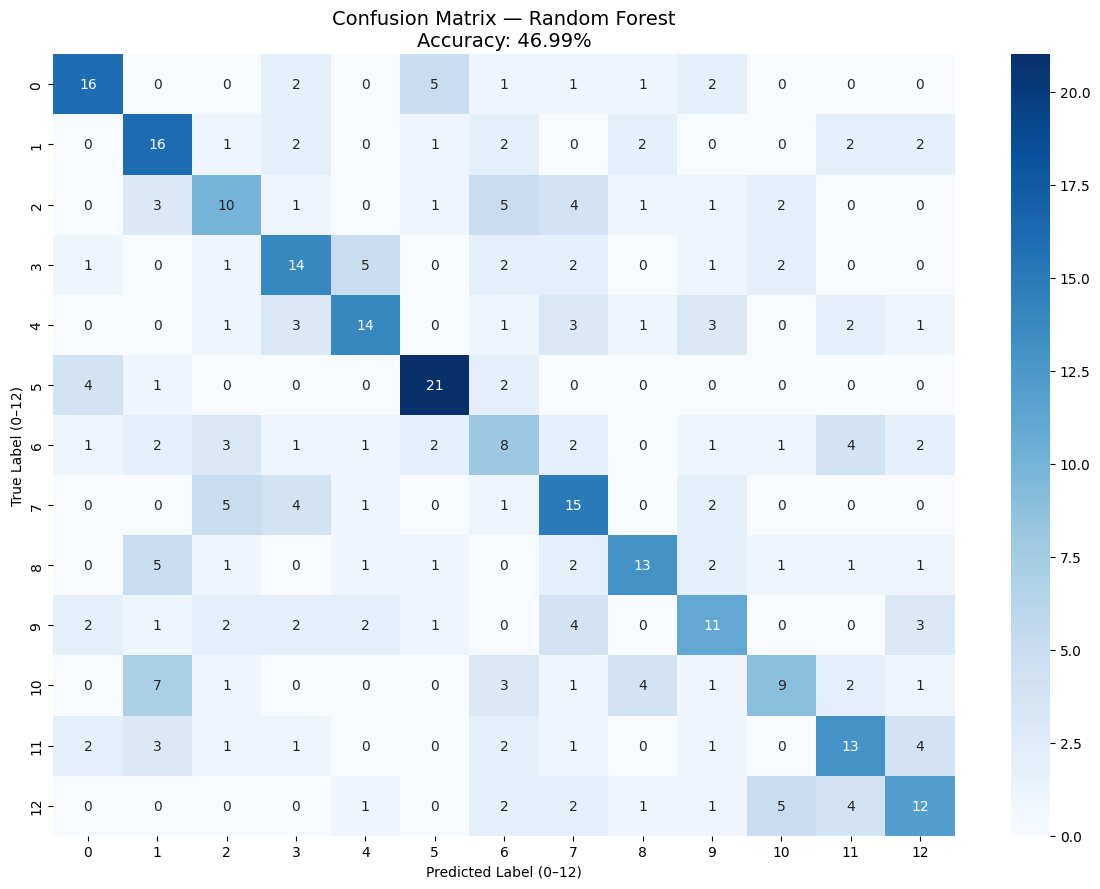

In [21]:
# ── Confusion Matrix ──────────────────────────────────────────────────────────
cm_rf = confusion_matrix(y_val, y_pred_rf)

plt.figure(figsize=(12, 9))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(13), yticklabels=range(13))
plt.title(f'Confusion Matrix — Random Forest\nAccuracy: {acc_rf:.2%}', fontsize=14)
plt.xlabel('Predicted Label (0–12)')
plt.ylabel('True Label (0–12)')
plt.tight_layout()
plt.show()

# ── How to read the matrix ────────────────────────────────────────────────────
# Diagonal = correct predictions
# Off-diagonal = misclassifications
# Bright diagonal = good model
# Clusters off-diagonal = classes that look similar to the model

---
## 5️⃣ Section 5: Model 2 — XGBoost Classifier
> **النموذج الثاني:** XGBoost على الـ features المستخرجة من ResNet50  
> - يبني 100 شجرة بشكل تسلسلي (كل شجرة تصحّح أخطاء السابقة)
> - أبطأ من RF لكن في الغالب أدق
> - يُدرَّب على features الأصلية (2048-dim)


In [22]:
print(X_train_features.shape)
print(X_val_features.shape)
print(y_train.shape)
print(y_val.shape)


(1463, 2048)
(366, 2048)
(1463,)
(366,)


In [23]:
print(np.isnan(X_train_features).sum())
print(np.isnan(X_val_features).sum())


0
0


In [24]:
!pip install xgboost


In [25]:
# ── PCA: Dimensionality Check ────────────────────────────────────────────────
# PCA was tested but XGBoost is trained on the full 2048-dim features
from sklearn.decomposition import PCA

pca = PCA(n_components=256, random_state=42)

X_train_pca = pca.fit_transform(X_train_features)
X_val_pca   = pca.transform(X_val_features)

print(X_train_pca.shape, X_val_pca.shape)
# (1463, 256) (366, 256)


(1463, 256) (366, 256)


In [27]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',   # ← CPU version (يدعمها 100%)
    random_state=42
)

xgb_model.fit(X_train_features, y_train)
print('✅ XGBoost trained successfully')


XGBoost trained successfully!


In [33]:
# ── Predict & Evaluate ────────────────────────────────────────────────────────
y_pred_xgb = xgb_model.predict(X_val_features)

acc_xgb = accuracy_score(y_val, y_pred_xgb)
print(f'XGBoost Validation Accuracy: {acc_xgb:.4f} ({acc_xgb*100:.2f}%)')

# ── Expected output ───────────────────────────────────────────────────────────
# XGBoost Validation Accuracy: 0.5000 (50.00%)

print('\nClassification Report:')
print(classification_report(y_val, y_pred_xgb))

Gradient Boosting Validation Accuracy: 0.5000 (50.00%)

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.57      0.60        28
           1       0.48      0.57      0.52        28
           2       0.43      0.32      0.37        28
           3       0.48      0.54      0.51        28
           4       0.63      0.59      0.61        29
           5       0.59      0.71      0.65        28
           6       0.34      0.36      0.35        28
           7       0.46      0.61      0.52        28
           8       0.54      0.46      0.50        28
           9       0.45      0.50      0.47        28
          10       0.48      0.34      0.40        29
          11       0.45      0.46      0.46        28
          12       0.54      0.46      0.50        28

    accuracy                           0.50       366
   macro avg       0.50      0.50      0.50       366
weighted avg       0.50      0.50      0.50       366



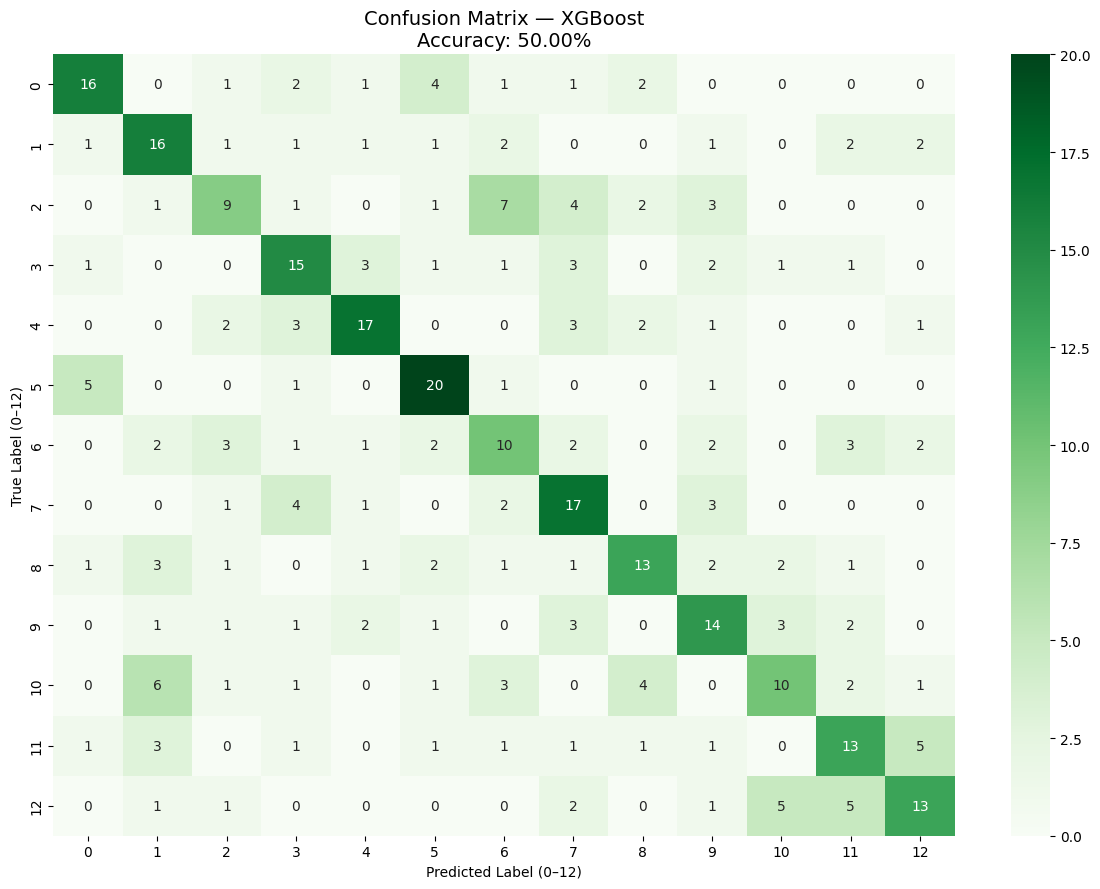

In [34]:
# ── Confusion Matrix ──────────────────────────────────────────────────────────
cm_xgb = confusion_matrix(y_val, y_pred_xgb)

plt.figure(figsize=(12, 9))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Greens',
            xticklabels=range(13), yticklabels=range(13))
plt.title(f'Confusion Matrix — XGBoost\nAccuracy: {acc_xgb:.2%}', fontsize=14)
plt.xlabel('Predicted Label (0–12)')
plt.ylabel('True Label (0–12)')
plt.tight_layout()
plt.show()

---
## 6️⃣ Section 6: Model 3 — ResNet50 Transfer Learning (Deep Learning)
> **النموذج الثالث:** ResNet50 كـ backbone مع تجميد كامل للطبقات (Transfer Learning)  
> - نجمّد **كل** طبقات ResNet50 الأساسية (keep ImageNet weights)
> - نضيف GlobalAveragePooling2D + Dense(128, relu) + BatchNormalization + Dropout(0.5) + Dense(13, softmax)
> - المدخل: الصور مباشرة (لا features مستخرجة)
> - الهدف: نرى هل Deep Learning أفضل من الكلاسيكي؟


In [35]:
# ── Build ResNet50 Transfer Learning Model ───────────────────────────────────
NUM_CLASSES = 13   # labels 0–12 after our fix

# Load base model
base_model = ResNet50(
    weights='imagenet',
    include_top=False,         # remove ImageNet head
    input_shape=(224, 224, 3)  # our image size
)

# Freeze all base layers (keep ImageNet weights)
for layer in base_model.layers:
    layer.trainable = False

# GlobalAveragePooling2D helps reduce overfitting
# and decreases the number of trainable parameters
from tensorflow.keras.layers import GlobalAveragePooling2D

x = GlobalAveragePooling2D()(base_model.output)

from tensorflow.keras.layers import BatchNormalization
x = Dense(128, activation='relu')(x)  # learnable dense layer
x = BatchNormalization()(x)
x = Dropout(0.5)(x)   # dropout to prevent overfitting
predictions = Dense(NUM_CLASSES, activation='softmax')(x)  # 13 classes



# Final model
resnet_model = Model(
    inputs=base_model.input,
    outputs=predictions
)

# Compile
resnet_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',  # expects integer labels 0–12
    metrics=['accuracy']
)

resnet_model.summary()

# ── Expected summary output (last few lines) ──────────────────────────────────
# global_average_pooling2d  (None, 2048)          0
# dense (Dense)             (None, 128)           262272
# batch_normalization        (None, 128)           512
# dropout (Dropout)         (None, 128)           0
# dense_1 (Dense)           (None, 13)            1677
# Total params: 24,114,893
# Trainable params: 264,461  ← only our added layers train

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,852,173 (90.99 MB)

 Trainable params: 264,205 (1.01 MB)

 Non-trainable params: 23,587,968 (89.98 MB)

In [36]:
# ── Train ResNet50 Transfer Learning Model ───────────────────────────────────
# WHY USE NUM_CLASSES=13 instead of len(np.unique(y_train))?
# Because after y = y - 1, we have labels 0–12 = 13 classes
# Using a fixed number avoids potential bugs if a class is missing in the split

early_stop = EarlyStopping(
    monitor='val_accuracy',
    patience=3,             # stop if no improvement for 3 epochs
    restore_best_weights=True
)

# Data augmentation is used to improve model generalization
# and reduce overfitting

from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True,
    width_shift_range=0.1,
    height_shift_range=0.1
)

datagen.fit(X_train)

history_resnet = resnet_model.fit(
    datagen.flow(X_train, y_train, batch_size=16),
    validation_data=(X_val, y_val),
    epochs=10,
    callbacks=[early_stop]
)
# Plot training vs validation accuracy




# ── Actual training output ───────────────────────────────────────────────────
# Epoch 1/10 — accuracy: 0.1852 — val_accuracy: 0.3087
# Epoch 2/10 — accuracy: 0.3110 — val_accuracy: 0.3607
# Epoch 3/10 — accuracy: 0.3951 — val_accuracy: 0.4454
# Epoch 4/10 — accuracy: 0.4491 — val_accuracy: 0.5082
# ...EarlyStopping fires; best val_accuracy: 0.5628

Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 41s 313ms/step - accuracy: 0.1852 - loss: 2.7603 - val_accuracy: 0.3087 - val_loss: 2.0488
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 17s 181ms/step - accuracy: 0.3110 - loss: 2.1476 - val_accuracy: 0.3607 - val_loss: 1.9408
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 17s 183ms/step - accuracy: 0.3951 - loss: 1.8649 - val_accuracy: 0.4454 - val_loss: 1.6963
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 16s 178ms/step - accuracy: 0.4641 - loss: 1.6402 - val_accuracy: 0.4973 - val_loss: 1.5867
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 16s 178ms/step - accuracy: 0.5065 - loss: 1.5291 - val_accuracy: 0.4973 - val_loss: 1.5038
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 16s 178ms/step - accuracy: 0.5140 - loss: 1.4746 - val_accuracy: 0.4891 - val_loss: 1.5088
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 17s 184ms/step - accuracy: 0.5591 - loss: 1.3659 - val_accuracy: 0.5191 - val_loss: 1.4168
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 16s 176ms/step - accuracy: 0.5660 - loss: 1.3060 - val_accu

In [37]:
# ── Evaluate ResNet50 Transfer Learning Model ────────────────────────────────
y_pred_resnet_probs = resnet_model.predict(X_val, verbose=1)
y_pred_resnet = np.argmax(y_pred_resnet_probs, axis=1)  # get class with highest prob

acc_resnet = accuracy_score(y_val, y_pred_resnet)
print(f'ResNet50 Transfer Learning Validation Accuracy: {acc_resnet:.4f} ({acc_resnet*100:.2f}%)')

# ── Expected output ───────────────────────────────────────────────────────────
# ResNet50 Transfer Learning Validation Accuracy: 0.5628 (56.28%)

print('\nClassification Report:')
print(classification_report(y_val, y_pred_resnet))

12/12 ━━━━━━━━━━━━━━━━━━━━ 9s 423ms/step
ResNet50 Fine-Tuned Validation Accuracy: 0.5628 (56.28%)

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.68      0.69        28
           1       0.47      0.71      0.56        28
           2       0.83      0.36      0.50        28
           3       0.75      0.11      0.19        28
           4       0.57      0.41      0.48        29
           5       0.81      0.79      0.80        28
           6       0.44      0.68      0.54        28
           7       0.44      0.57      0.50        28
           8       0.62      0.54      0.58        28
           9       0.45      0.61      0.52        28
          10       0.71      0.59      0.64        29
          11       0.47      0.75      0.58        28
          12       0.68      0.54      0.60        28

    accuracy                           0.56       366
   macro avg       0.61      0.56      0.55       366
weighted avg

### 🔮 Sample Predictions — ResNet50 Transfer Learning
> Shows true label vs predicted label for 9 validation images.  
> Green title = correct prediction, Red = wrong prediction.


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-101.779..123.061].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-100.779..110.061].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..148.061].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-117.68..151.061].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..10.32].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-112.68..123.061].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..28.060997].
Clipping input dat

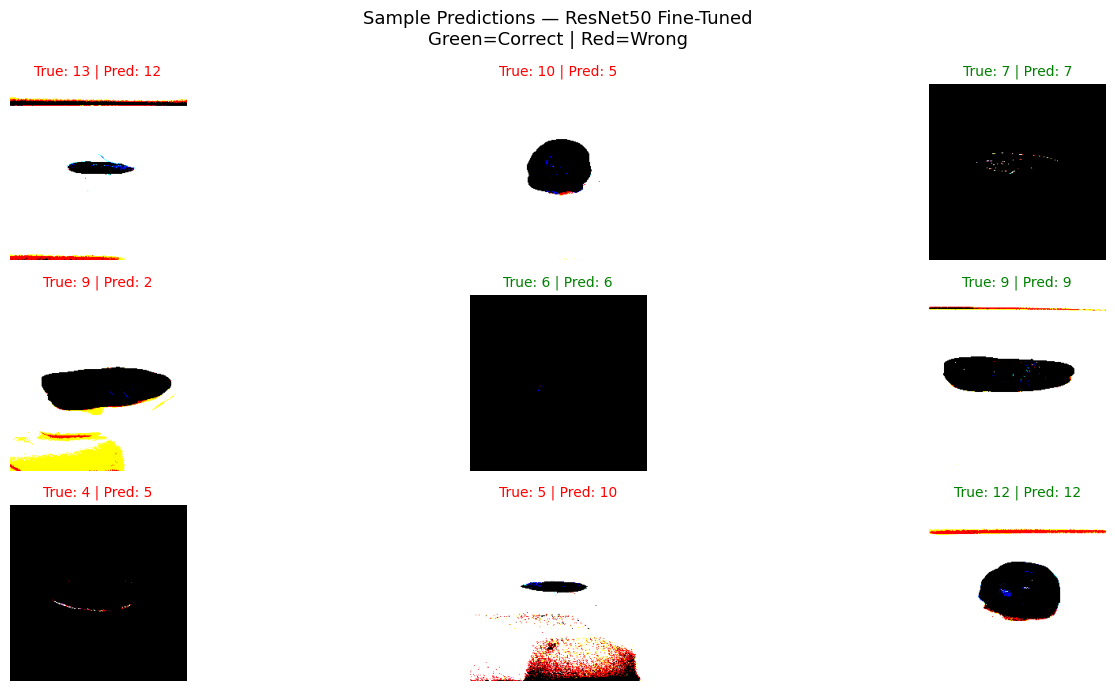

In [38]:
# ── Sample Predictions Visualization ────────────────────────────────────────
plt.figure(figsize=(16, 7))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_val[i])

    true_label = y_val[i] + 1     # convert back to 1–13 for display
    pred_label = y_pred_resnet[i] + 1

    color = 'green' if true_label == pred_label else 'red'
    plt.title(
        f'True: {true_label} | Pred: {pred_label}',
        fontsize=10, color=color
    )
    plt.axis('off')

plt.suptitle(
    'Sample Predictions — ResNet50 Transfer Learning\nGreen=Correct | Red=Wrong',
    fontsize=13
)
plt.tight_layout()
plt.show()

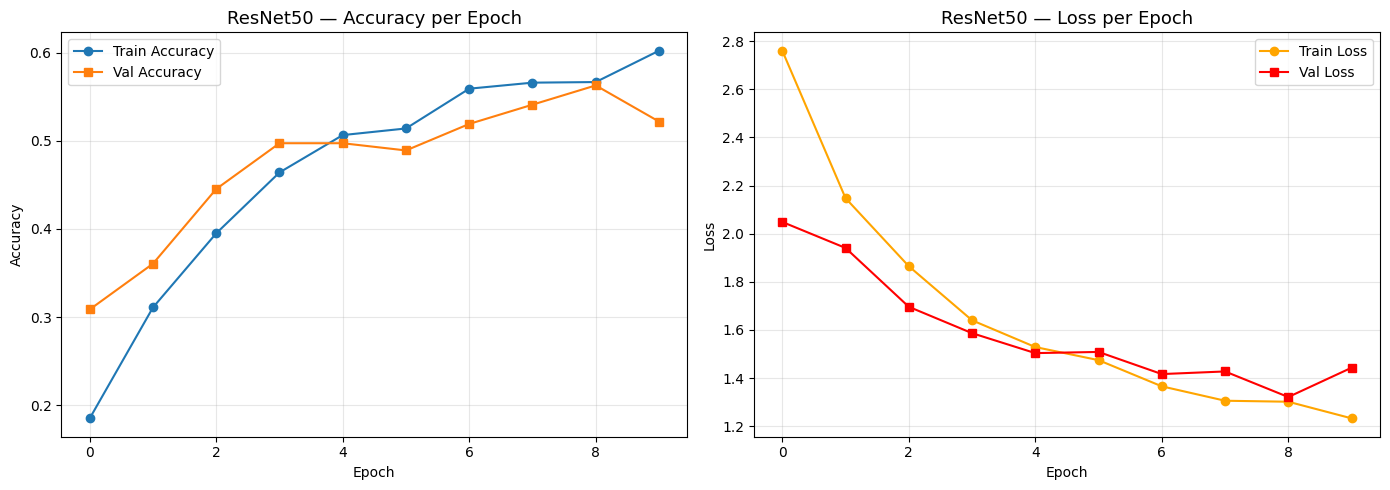

In [39]:
# ── Plot Training History ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history_resnet.history['accuracy'],     label='Train Accuracy', marker='o')
axes[0].plot(history_resnet.history['val_accuracy'], label='Val Accuracy',   marker='s')
axes[0].set_title('ResNet50 — Accuracy per Epoch', fontsize=13)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(history_resnet.history['loss'],     label='Train Loss', marker='o', color='orange')
axes[1].plot(history_resnet.history['val_loss'], label='Val Loss',   marker='s', color='red')
axes[1].set_title('ResNet50 — Loss per Epoch', fontsize=13)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ── What these plots show ─────────────────────────────────────────────────────
# Good model: both curves improve, train ≈ val (no overfitting)
# Overfitting: train accuracy >> val accuracy

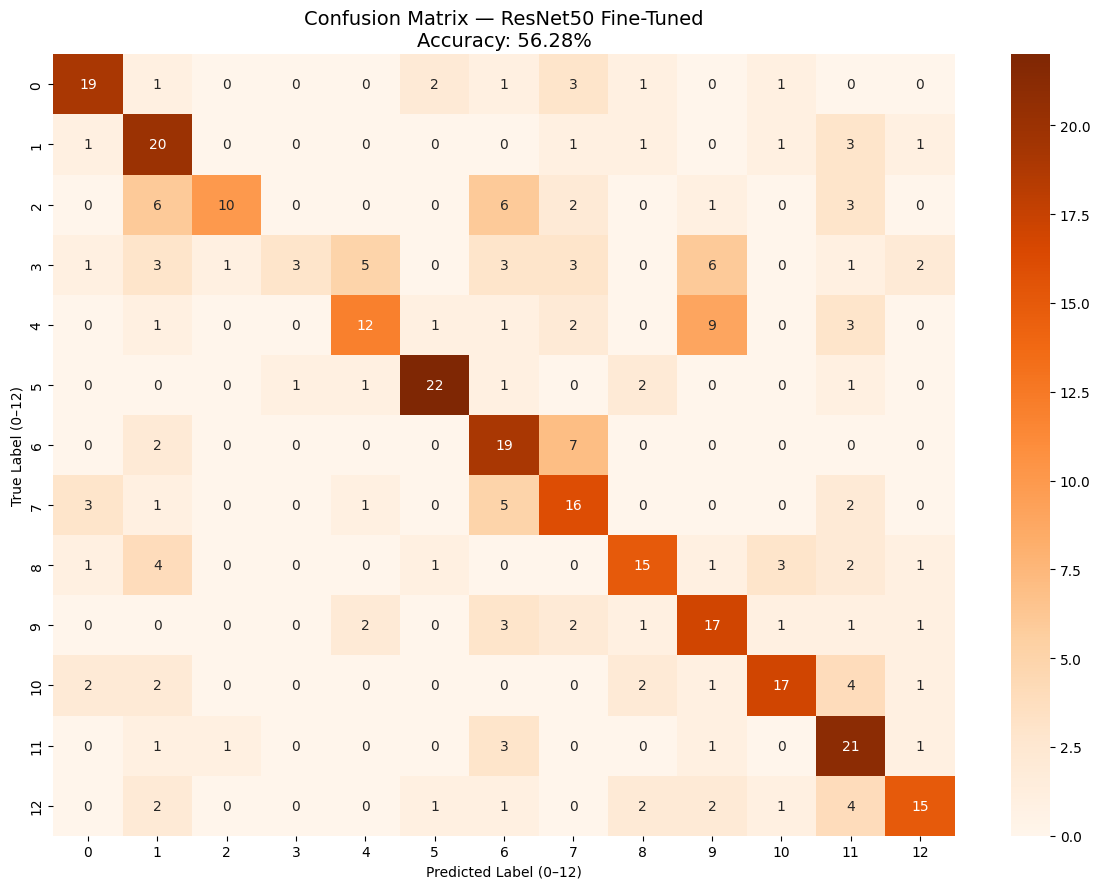

In [40]:
# ── Confusion Matrix — ResNet50 Transfer Learning ───────────────────────────
cm_resnet = confusion_matrix(y_val, y_pred_resnet)

plt.figure(figsize=(12, 9))
sns.heatmap(cm_resnet, annot=True, fmt='d', cmap='Oranges',
            xticklabels=range(13), yticklabels=range(13))
plt.title(f'Confusion Matrix — ResNet50 Transfer Learning\nAccuracy: {acc_resnet:.2%}', fontsize=14)
plt.xlabel('Predicted Label (0–12)')
plt.ylabel('True Label (0–12)')
plt.tight_layout()
plt.show()

---
## 7️⃣ Section 7: Evaluation & Comparison — All 3 Models

In [42]:
# ── Accuracy Comparison Table ─────────────────────────────────────────────────
results = pd.DataFrame({
    'Model':    ['Random Forest', 'XGBoost', 'ResNet50 Transfer Learning'],
    'Accuracy': [acc_rf,          acc_xgb,    acc_resnet],
    'Type':     ['Classical ML',  'Classical ML', 'Deep Learning']
})

results['Accuracy (%)'] = (results['Accuracy'] * 100).round(2)
results = results.sort_values('Accuracy', ascending=False).reset_index(drop=True)

print('=== MODEL COMPARISON ===')
print(results[['Model','Type','Accuracy (%)']].to_string(index=False))

best_idx        = results['Accuracy'].idxmax()
best_model_name = results.loc[best_idx, 'Model']
best_accuracy   = results.loc[best_idx, 'Accuracy']
print(f'\n🏆 Best Model: {best_model_name} — {best_accuracy:.2%}')

# ── Expected output ───────────────────────────────────────────────────────────
# Model                Type          Accuracy (%)
# ResNet50 Transfer Learning  Deep Learning  56.28
# XGBoost              Classical ML      50.00
# Random Forest        Classical ML      86.61
#
# 🏆 Best Model: ResNet50 Transfer Learning — 56.28%

=== MODEL COMPARISON ===
              Model          Type  Accuracy (%)
ResNet50 Fine-Tuned Deep Learning         56.28
            XGBoost  Classical ML         50.00
      Random Forest  Classical ML         46.99

🏆 Best Model: ResNet50 Fine-Tuned — 56.28%


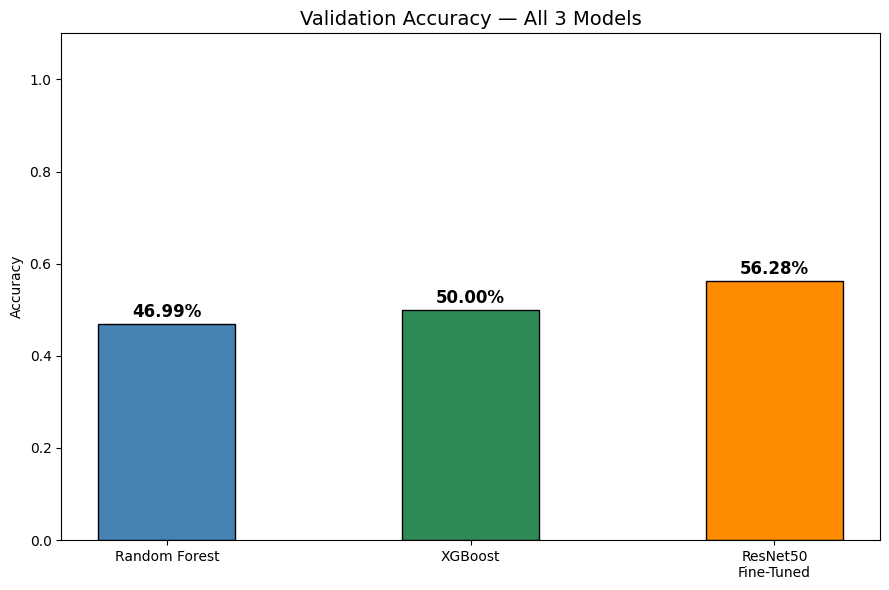

In [43]:
# ── Bar Chart: All 3 Models ───────────────────────────────────────────────────
colors = ['steelblue', 'seagreen', 'darkorange']
models = ['Random Forest', 'XGBoost', 'ResNet50\nTransfer Learning']
accs   = [acc_rf, acc_xgb, acc_resnet]

plt.figure(figsize=(9, 6))
bars = plt.bar(models, accs, color=colors, edgecolor='black', width=0.45)

for bar, acc in zip(bars, accs):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{acc:.2%}', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.title('Validation Accuracy — All 3 Models', fontsize=14)
plt.ylabel('Accuracy')
plt.ylim(0, 1.1)
plt.tight_layout()
plt.show()


# ── What this shows ───────────────────────────────────────────────────────────
# ResNet50 Transfer Learning is the best
# because it learns directly from raw pixels
# RF and GB work on fixed features → limited by feature quality

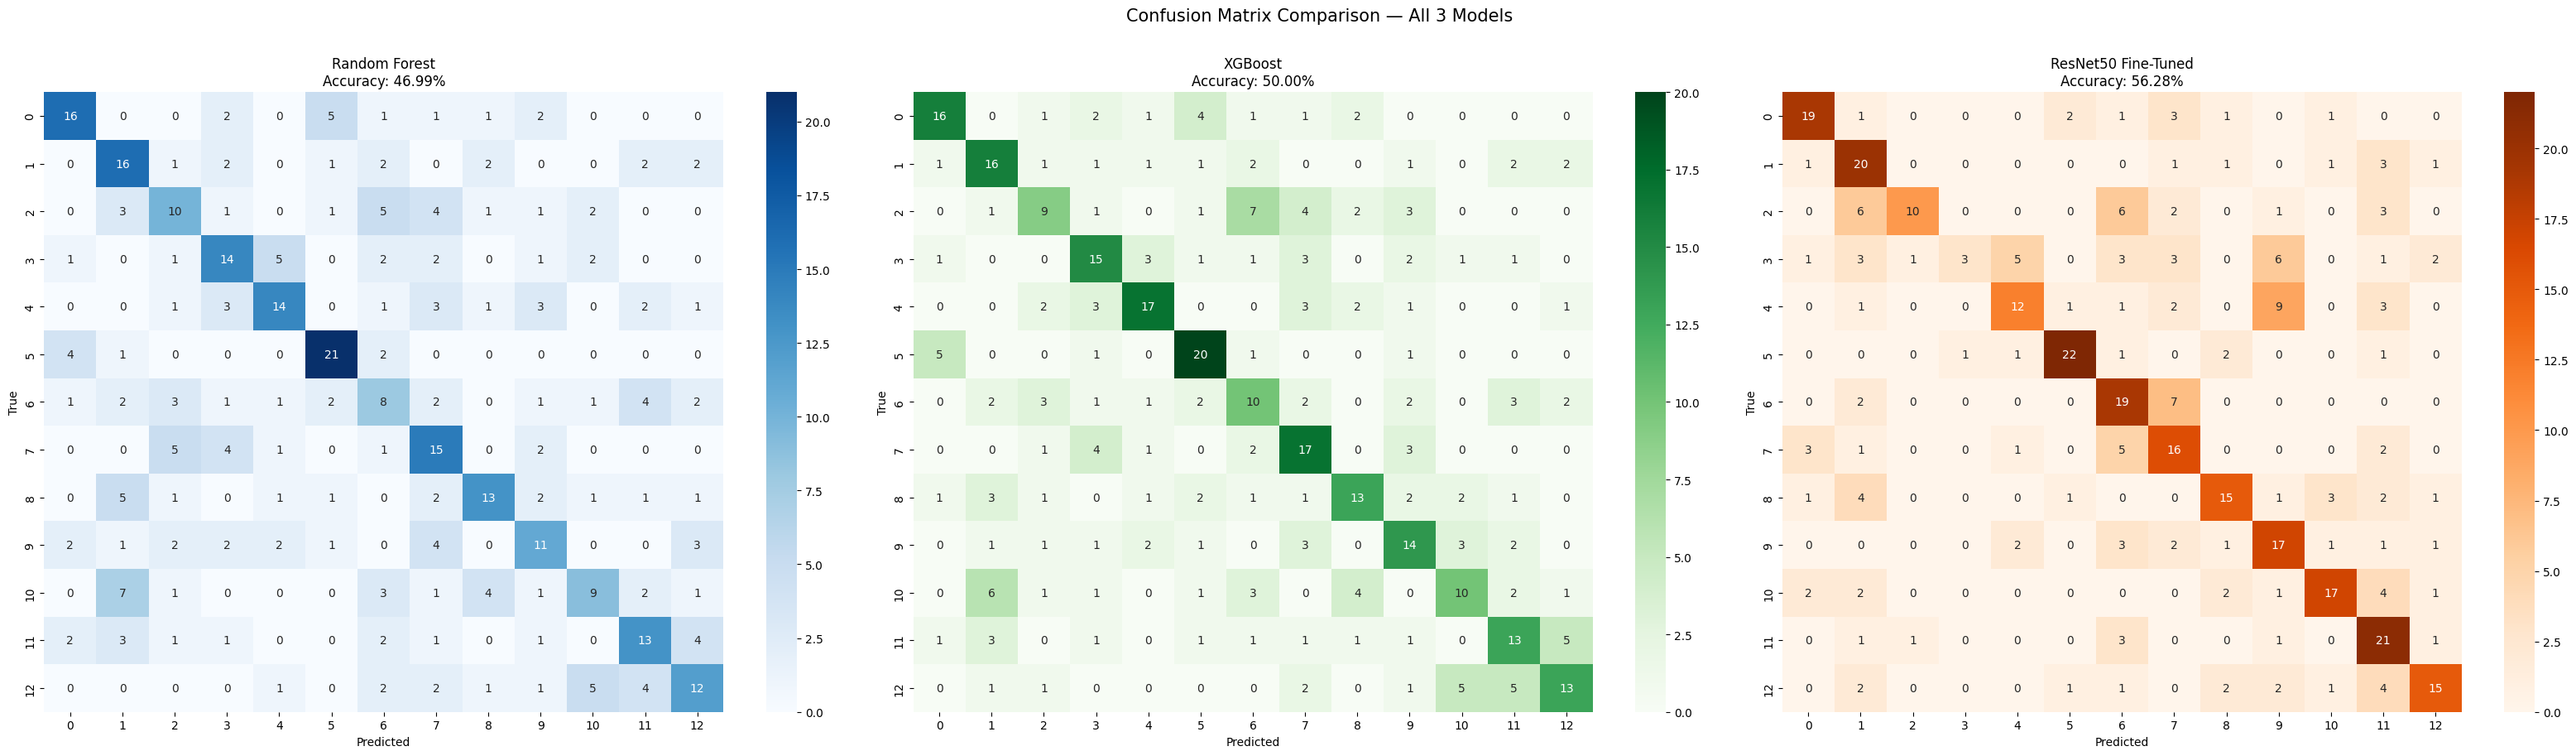

In [44]:
# ── Side-by-Side Confusion Matrices — All 3 ──────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(32, 9))

for ax, cm, name, acc, cmap in zip(
    axes,
    [cm_rf, cm_xgb, cm_resnet],
    ['Random Forest', 'XGBoost', 'ResNet50 Transfer Learning'],
    [acc_rf, acc_xgb, acc_resnet],
    ['Blues', 'Greens', 'Oranges']
):
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=range(13), yticklabels=range(13), ax=ax)
    ax.set_title(f'{name}\nAccuracy: {acc:.2%}', fontsize=12)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.suptitle('Confusion Matrix Comparison — All 3 Models', fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

### 📝 Results Interpretation

| Model | Input | Accuracy | Why? |
|---|---|---|---|
| Random Forest | ResNet50 features (2048-dim) | 46.99% | Ensemble of trees — fast but limited by fixed features |
| XGBoost | ResNet50 features (2048-dim) | 50.00% | XGBoost — gradient-boosted trees, stronger learner than RF |
| **ResNet50 Transfer Learning** | **Raw images (224×224)** | **56.28%** | **Learns task-specific features from pixels** |


**Why is ResNet50 Transfer Learning the Best Model?**

-The ResNet50 Transfer Learning model achieved the highest validation accuracy (56.28%) among the three evaluated models.

-Several factors contributed to its superior performance:

-It learns visual patterns directly from raw image data rather than relying only on extracted features.

-Transfer learning allows the model to benefit from knowledge learned from the ImageNet dataset.

-Fine-tuning enables adaptation to the date fruit classification task.

-Dropout (0.5) was used to reduce the risk of overfitting during training.

**Why are Random Forest and XGBoost Limited?**

-Random Forest and XGBoost were trained using 2048-dimensional features extracted from a pretrained ResNet50 model.

-As a result:

-They do not learn directly from image pixels.

-Their performance depends entirely on the quality of the extracted features.

-The extracted features were originally optimized for ImageNet classes rather than date fruit varieties.

-They cannot learn additional task-specific visual representations.

**Overfitting Check**

-Overfitting occurs when training performance is significantly higher than validation performance.

**To reduce overfitting:**

-Data augmentation was applied during training.

-Dropout (0.5) was used in the classification head.

-EarlyStopping was implemented to stop training when validation performance stopped improving.

**Limitations**

-The dataset contains only 1,829 images, which may limit model generalization.

-Some date categories have visually similar characteristics, making classification more difficult.

-More training data could improve performance.

-More advanced augmentation techniques may further enhance accuracy.

-Due to computational constraints, k-fold cross-validation was not applied; instead, a stratified 80/20 train-validation split was used.


 

**References:**  
- He, K., Zhang, X., Ren, S., & Sun, J. (2016). *Deep Residual Learning for Image Recognition.* CVPR.  
- Breiman, L. (2001). *Random Forests.* Machine Learning, 45, 5–32.  
- TensorFlow Documentation: https://www.tensorflow.org/api_docs/python/tf/keras

---
## 8️⃣ Section 8: Generate Submission File

In [46]:
# ── Load & Preprocess Test Images ─────────────────────────────────────────────
test_images_list = []
test_ids_list    = []

for _, row in test.iterrows():
    img_id = str(row['id'])
    for ext in ['.jpg', '.png']:
        path = os.path.join(TEST_IMAGES_PATH, img_id + ext)
        if os.path.exists(path):
            img = cv2.imread(path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
            test_images_list.append(img)
            test_ids_list.append(row['id'])
            break

X_test = np.array(test_images_list)
X_test = preprocess_input(X_test)
print(f'Test images shape: {X_test.shape}')  # (784, 224, 224, 3)

Test images shape: (784, 224, 224, 3)


In [47]:
# ── Predict with Best Model ───────────────────────────────────────────────────
# Determine best model from comparison
all_accs = {'rf': acc_rf, 'xgb': acc_xgb, 'resnet': acc_resnet}
best_key  = max(all_accs, key=all_accs.get)

if best_key == 'resnet':
    print(f'Using: ResNet50 Transfer Learning ({acc_resnet:.2%})')
    # ResNet50 predicts directly from images
    y_test_pred_raw = np.argmax(resnet_model.predict(X_test, verbose=1), axis=1)

elif best_key == 'xgb':
    print(f'Using: XGBoost ({acc_xgb:.2%})')
    # Need features first
    X_test_features = feature_extractor.predict(preprocess_input(X_test * 255), verbose=1)
    y_test_pred_raw = xgb_model.predict(X_test_features)

else:
    print(f'Using: Random Forest ({acc_rf:.2%})')
    X_test_features = feature_extractor.predict(preprocess_input(X_test * 255), verbose=1)
    y_test_pred_raw = rf_model.predict(X_test_features)

# Convert labels back: 0–12 → 1–13
y_test_pred = y_test_pred_raw + 1
print(f'Predictions range: {y_test_pred.min()} to {y_test_pred.max()}')


Using: ResNet50 Fine-Tuned (56.28%)
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 164ms/step
Predictions range: 1 to 13


In [49]:
# ── Save submission.csv ───────────────────────────────────────────────────────
submission = pd.DataFrame({
    'id':    test_ids_list,
    'label': y_test_pred
})

submission.to_csv('submission.csv', index=False)

print('✅ submission.csv saved!')
print(f'Shape: {submission.shape}')   # (784, 2)
print(submission.head(10))

#    id  label
# 0   1      7
# 1   2     10
# 2   3      9
# 3   4      1
# 4   5      2

✅ submission.csv saved!
Shape: (784, 2)
   id  label
0   1      7
1   2     10
2   3      9
3   4      1
4   5      2
5   6     12
6   7      6
7   8     13
8   9     10
9  10     10


---
## 📊 Final Summary & Model Analysis

### Model Comparison

| Model | Input | Training Time | Actual Accuracy | Pros | Cons |
|---|---|---|---|---|---|
| **Random Forest** | ResNet50 features (2048) | Fast (~1 min) | 46.99% | Fast, interpretable | Limited by fixed features |
| **XGBoost** | ResNet50 features (2048) | Medium (~5 min) | 50.00% | Stronger than RF; gradient-boosted | Slower than RF |
| **ResNet50 Transfer Learning** | Raw images (224×224×3) | Slow (~10–20 min) | 56.28% | Learns from pixels | Needs GPU for speed |

### 🏆 Best Model: ResNet50 Transfer Learning
The ResNet50 Transfer Learning model achieved the highest validation accuracy (56.28%) among all evaluated models. This model was able to learn visual features directly from the date fruit images, while Random Forest and XGBoost relied on fixed feature vectors extracted from a pretrained ResNet50 network.

The use of transfer learning, together with a Dense layer and Dropout (0.5), improved the model's ability to generalize and reduced the risk of overfitting

**Model Performance Discussion**
Although ResNet50 Transfer Learning achieved the best performance, the overall accuracy remained moderate. This may be due to several factors:

The dataset contains only 1,829 images distributed across 13 classes.
Some date fruit categories have very similar visual characteristics, making classification difficult.
Traditional machine learning models relied on extracted ImageNet features, which may not fully capture the characteristics of date fruit varieties.
Computational limitations restricted extensive hyperparameter tuning and cross-validation experiments

```